# 04 — Model Development

เป้าหมายของ Phase 4 คือใช้ **logical features ที่ Phase 3 เลือกไว้** แล้วเลือกโมเดล, hyperparameters และ decision threshold โดยไม่แตะ test set

ลำดับการตัดสินใจ:

```text
Train
→ 5-fold Stratified CV
→ ใช้ Feature ที่ Phase 3 เลือกไว้แบบคงที่
→ Tune model parameters
→ เลือกโมเดลด้วย PR-AUC
→ ตรวจบน Validation หนึ่งครั้ง
→ เลือก Threshold จาก Validation
→ Refit Pipeline ด้วย Train + Validation
→ บันทึก Final Pipeline สำหรับ Phase 5
```

Test set จะเปิดใช้เฉพาะ Phase 5

In [14]:
from pathlib import Path
import importlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

RANDOM_STATE = 42
TARGET = "stroke"
TARGET_RECALL = 0.80

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

# Reload project code when the notebook kernel has been running for a while.
import src.features.selection as selection_module
import src.features.stroke_features as feature_module
import src.modeling.pipeline as pipeline_module

importlib.reload(selection_module)
importlib.reload(feature_module)
importlib.reload(pipeline_module)

FixedFeatureSelector = selection_module.FixedFeatureSelector
StrokeFeatureEngineer = feature_module.StrokeFeatureEngineer
get_required_raw_features = feature_module.get_required_raw_features
build_model_pipeline = pipeline_module.build_model_pipeline
split_features_target = pipeline_module.split_features_target

## 1. Load development data

Train ใช้สำหรับ model selection และ tuning ผ่าน CV ส่วน validation เก็บไว้ตรวจโมเดลที่ชนะและเลือก threshold

In [15]:
train_path = PROCESSED_DIR / "train.csv"
validation_path = PROCESSED_DIR / "validation.csv"
if not train_path.exists() or not validation_path.exists():
    raise FileNotFoundError("Run 01_data_engineering.ipynb first.")

train_df = pd.read_csv(train_path)
validation_df = pd.read_csv(validation_path)
X_train, y_train = split_features_target(train_df, target=TARGET)
X_validation, y_validation = split_features_target(validation_df, target=TARGET)

print("Train:", X_train.shape, "stroke rate:", round(y_train.mean(), 4))
print("Validation:", X_validation.shape, "stroke rate:", round(y_validation.mean(), 4))

feature_manifest_path = MODEL_DIR / "feature_manifest.json"
if not feature_manifest_path.exists():
    raise FileNotFoundError(
        "Run 03_feature_engineering.ipynb through the manifest-saving cell first."
    )
with feature_manifest_path.open("r", encoding="utf-8") as file:
    feature_manifest = json.load(file)

frozen_features = tuple(feature_manifest["selected_logical_features"])
phase3_required_raw_features = feature_manifest["required_raw_features"]
print("\nFrozen features from Phase 3:")
print(frozen_features)
print("Required raw inputs from Phase 3:")
print(phase3_required_raw_features)

Train: (3577, 10) stroke rate: 0.0486
Validation: (766, 10) stroke rate: 0.0483

Frozen features from Phase 3:
('age', 'ever_married', 'bmi', 'age_squared', 'bmi_squared', 'age_glucose_interaction', 'bmi_glucose_interaction', 'comorbidity_count')
Required raw inputs from Phase 3:
['age', 'hypertension', 'heart_disease', 'ever_married', 'avg_glucose_level', 'bmi']


## 2. Decisions and reasons

### Primary metric: PR-AUC

ข้อมูล stroke ไม่สมดุลมาก Accuracy จึงอาจสูงแม้โมเดลทำนายว่าไม่เป็น stroke เกือบทุกคน PR-AUC เน้นคุณภาพการค้นหา positive class จึงใช้เลือกโมเดล ส่วน ROC-AUC, Recall และ F1 ใช้ประกอบ

### Imbalance: Class weight

ใช้ class weighting ก่อน เพราะไม่สร้างผู้ป่วยสังเคราะห์และอยู่ภายใน estimator โดยธรรมชาติ ยังไม่ใช้ SMOTE เพราะข้อมูลมีทั้ง numeric/categorical และตัวอย่างสังเคราะห์อาจไม่สมเหตุผลทางคลินิก หากต้องทดลองภายหลังต้องใช้ `imblearn.Pipeline` ภายใน CV เท่านั้น

### Search: Randomized search

ใช้ RandomizedSearchCV เพื่อสำรวจค่าหลายแบบโดยไม่เพิ่มจำนวนการ fit มากเกินไป ทุก candidate ใช้ folds ชุดเดียวกันและ Feature ชุดเดียวกับที่ Phase 3 เลือกไว้ Phase 4 tune เฉพาะ model parameters

## 3. Candidate models

เลือกโมเดลที่มีลักษณะต่างกันเพื่อให้การเปรียบเทียบมีความหมาย:

| Model | เหตุผลที่เลือก |
|---|---|
| Logistic Regression | Baseline เชิงเส้น อธิบายง่าย และเหมาะกับข้อมูลไม่ใหญ่มาก |
| Random Forest | จับ nonlinear relationships และ interactions ได้โดยไม่ต้องกำหนดรูปแบบล่วงหน้า |
| HistGradientBoosting | Boosting มักทำงานได้ดีกับ tabular data และจับรูปแบบซับซ้อนได้ |

Preprocessor ส่ง dense matrix เพราะ dataset นี้เล็กและ HistGradientBoosting ต้องการ dense input

In [16]:
model_specs = {
    "logistic_regression": {
        "estimator": LogisticRegression(
            class_weight="balanced",
            solver="liblinear",
            max_iter=3000,
            random_state=RANDOM_STATE,
        ),
        "params": {
            "model__C": np.logspace(-3, 2, 20).tolist(),
            "model__penalty": ["l1", "l2"],
        },
    },
    "random_forest": {
        "estimator": RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        "params": {
            "model__n_estimators": [200, 400, 600],
            "model__max_depth": [None, 4, 8, 12],
            "model__min_samples_leaf": [1, 3, 5, 10],
            "model__max_features": ["sqrt", 0.5, 1.0],
            "model__class_weight": ["balanced", "balanced_subsample"],
        },
    },
    "hist_gradient_boosting": {
        "estimator": HistGradientBoostingClassifier(
            class_weight="balanced",
            early_stopping=True,
            random_state=RANDOM_STATE,
        ),
        "params": {
            "model__learning_rate": [0.02, 0.05, 0.1, 0.2],
            "model__max_iter": [100, 200, 300],
            "model__max_leaf_nodes": [7, 15, 31],
            "model__min_samples_leaf": [10, 20, 30],
            "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
        },
    },
}

list(model_specs)

['logistic_regression', 'random_forest', 'hist_gradient_boosting']

## 4. Tune each end-to-end Pipeline on train CV

ทุก Pipeline มีลำดับเดียวกัน: feature engineering → เลือก Feature ตาม manifest จาก Phase 3 → preprocessing → model ดังนั้นทุกโมเดลถูกเปรียบเทียบบน Feature ชุดเดียวกัน ส่วน median, scaler, one-hot categories และ model parameters ยังถูกเรียนรู้ใหม่ในแต่ละ training fold

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "f1": "f1",
}

searches = {}
comparison_rows = []

for model_name, spec in model_specs.items():
    print(f"Searching {model_name}...")
    pipeline = build_model_pipeline(
        estimator=spec["estimator"],
        feature_engineer=StrokeFeatureEngineer(),
        feature_selector=FixedFeatureSelector(features=frozen_features),
    )
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=spec["params"],
        n_iter=25,
        scoring=scoring,
        refit="pr_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[model_name] = search

    best_index = search.best_index_
    comparison_rows.append({
        "model": model_name,
        "cv_pr_auc": search.cv_results_["mean_test_pr_auc"][best_index],
        "cv_pr_auc_std": search.cv_results_["std_test_pr_auc"][best_index],
        "cv_roc_auc": search.cv_results_["mean_test_roc_auc"][best_index],
        "cv_recall_at_0.5": search.cv_results_["mean_test_recall"][best_index],
        "cv_f1_at_0.5": search.cv_results_["mean_test_f1"][best_index],
        "selected_feature_count": len(frozen_features),
        "best_params": search.best_params_,
    })
    print(f"Best CV PR-AUC: {search.best_score_:.4f}\n")

model_comparison = pd.DataFrame(comparison_rows).sort_values("cv_pr_auc", ascending=False)
display(model_comparison)

Searching logistic_regression...


c:\Users\Acer\Desktop\Study\KU\ML\Assignments\Assignment3\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best CV PR-AUC: 0.2365

Searching random_forest...
Best CV PR-AUC: 0.2518

Searching hist_gradient_boosting...
Best CV PR-AUC: 0.2434



,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_recall_at_0.5,cv_f1_at_0.5,selected_feature_count,best_params
1,random_forest,0.251768,0.049962,0.848536,0.844874,0.208537,8,"{'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 4, 'mo..."
2,hist_gradient_boosting,0.243383,0.041308,0.847377,0.776134,0.238845,8,"{'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 7, 'model__max_iter': 200, 'model__learning_rate': 0.2, 'mo..."
0,logistic_regression,0.236453,0.026079,0.855220,0.816134,0.235710,8,"{'model__penalty': 'l2', 'model__C': 16.23776739188721}"


## 5. Select the model from train CV

เลือกโมเดลจาก CV PR-AUC เท่านั้น ไม่เลือกจาก validation เพื่อให้ validation ยังเป็นการตรวจอิสระหนึ่งครั้ง

In [18]:
selected_model_name = model_comparison.iloc[0]["model"]
selected_search = searches[selected_model_name]
selected_pipeline = selected_search.best_estimator_

print("Selected model:", selected_model_name)
print(f"Train CV PR-AUC: {selected_search.best_score_:.4f}")
print("Best parameters:")
display(pd.Series(selected_search.best_params_, name="value").to_frame())

Selected model: random_forest
Train CV PR-AUC: 0.2518
Best parameters:


,value
model__n_estimators,200
model__min_samples_leaf,5
model__max_features,sqrt
model__max_depth,4
model__class_weight,balanced


## 6. Validate the selected Pipeline

Validation ผ่าน end-to-end Pipeline โดยตรง ค่า 0.5 ด้านล่างเป็น default threshold และยังไม่ใช่ threshold สุดท้าย

In [19]:
validation_probability = selected_pipeline.predict_proba(X_validation)[:, 1]
validation_prediction_05 = (validation_probability >= 0.5).astype(int)

validation_pr_auc = average_precision_score(y_validation, validation_probability)
validation_roc_auc = roc_auc_score(y_validation, validation_probability)
print(f"Validation PR-AUC:  {validation_pr_auc:.4f}")
print(f"Validation ROC-AUC: {validation_roc_auc:.4f}")
print("\nAt threshold 0.5:")
print(classification_report(y_validation, validation_prediction_05, digits=4, zero_division=0))

Validation PR-AUC:  0.2508
Validation ROC-AUC: 0.8453

At threshold 0.5:
              precision    recall  f1-score   support

           0     0.9919    0.6749    0.8033       729
           1     0.1222    0.8919    0.2150        37

    accuracy                         0.6854       766
   macro avg     0.5571    0.7834    0.5091       766
weighted avg     0.9499    0.6854    0.7748       766



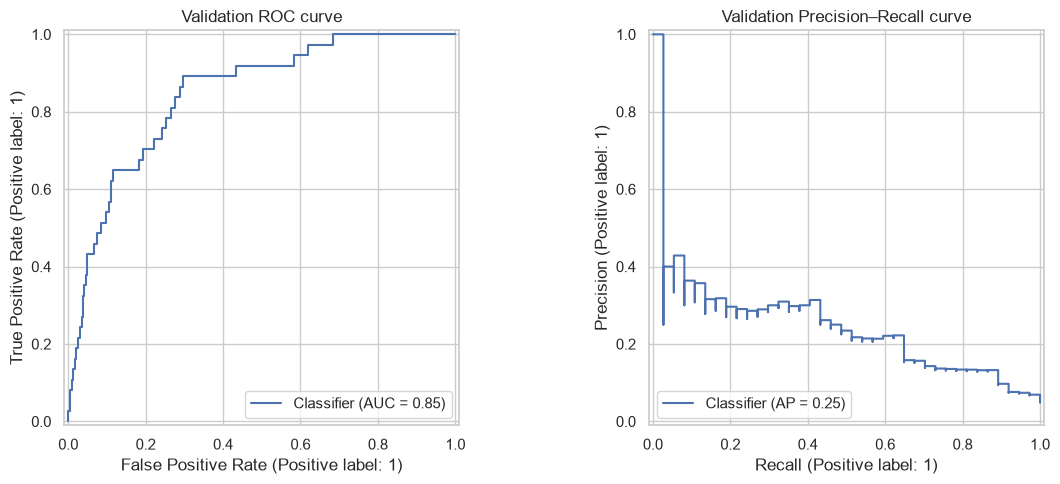

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_validation, validation_probability, ax=axes[0])
axes[0].set_title("Validation ROC curve")
PrecisionRecallDisplay.from_predictions(y_validation, validation_probability, ax=axes[1])
axes[1].set_title("Validation Precision–Recall curve")
plt.tight_layout()
plt.show()

## 7. Choose a decision threshold

ใช้ validation เลือก threshold โดยตั้งเป้า Recall อย่างน้อย 80% แล้วเลือก threshold ที่ให้ Precision สูงที่สุดภายใต้เงื่อนไขนั้น

เหตุผล: ในงานคัดกรอง การพลาดผู้มีความเสี่ยง (false negative) มักมีต้นทุนสูง แต่ค่า 80% เป็น **project assumption** ไม่ใช่เกณฑ์ทางการแพทย์ ก่อนใช้งานจริงต้องกำหนดร่วมกับผู้เชี่ยวชาญและดูทรัพยากรสำหรับติดตามผล หากไม่มี threshold ใดถึงเป้า จะเลือกค่า F2 สูงสุดซึ่งให้น้ำหนัก Recall มากกว่า Precision

In [21]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_validation, validation_probability
)
threshold_table = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision_values[:-1],
    "recall": recall_values[:-1],
})
threshold_table["f2"] = (
    5 * threshold_table["precision"] * threshold_table["recall"]
    / (4 * threshold_table["precision"] + threshold_table["recall"]).replace(0, np.nan)
).fillna(0)

eligible = threshold_table[threshold_table["recall"] >= TARGET_RECALL]
if not eligible.empty:
    chosen_row = eligible.sort_values(
        ["precision", "threshold"], ascending=False
    ).iloc[0]
    threshold_reason = f"highest precision with recall >= {TARGET_RECALL:.0%}"
else:
    chosen_row = threshold_table.loc[threshold_table["f2"].idxmax()]
    threshold_reason = "maximum F2 because the recall target was unreachable"

selected_threshold = float(chosen_row["threshold"])
print(f"Selected threshold: {selected_threshold:.4f}")
print("Reason:", threshold_reason)
display(chosen_row.to_frame("value"))

Selected threshold: 0.5531
Reason: highest precision with recall >= 80%


,value
threshold,0.553132
precision,0.133929
recall,0.810811
f2,0.403226


,threshold,precision,recall,f1
0,0.5000,0.1222,0.8919,0.2150
1,0.5531,0.1339,0.8108,0.2299


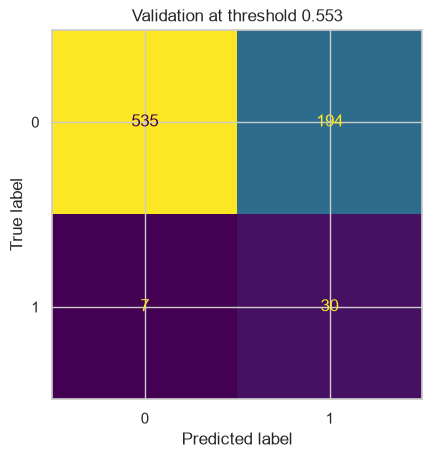

In [22]:
validation_prediction = (validation_probability >= selected_threshold).astype(int)

threshold_comparison = pd.DataFrame([
    {
        "threshold": 0.5,
        "precision": precision_score(y_validation, validation_prediction_05, zero_division=0),
        "recall": recall_score(y_validation, validation_prediction_05),
        "f1": f1_score(y_validation, validation_prediction_05),
    },
    {
        "threshold": selected_threshold,
        "precision": precision_score(y_validation, validation_prediction, zero_division=0),
        "recall": recall_score(y_validation, validation_prediction),
        "f1": f1_score(y_validation, validation_prediction),
    },
])
display(threshold_comparison.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_validation, validation_prediction, colorbar=False
)
plt.title(f"Validation at threshold {selected_threshold:.3f}")
plt.show()

## 8. Refit the frozen configuration on train + validation

หลังเลือก model, hyperparameters และ threshold เสร็จแล้ว จึงรวม train+validation เพื่อให้ Final Pipeline เรียนรู้จาก development data มากขึ้น Feature list ยังคงเป็นผลจาก Phase 3 และ configuration จะไม่เปลี่ยนหลังเห็นผล test

In [23]:
development_df = pd.concat([train_df, validation_df], ignore_index=True)
X_development, y_development = split_features_target(development_df, target=TARGET)

final_pipeline = clone(selected_pipeline)
final_pipeline.fit(X_development, y_development)

final_selector = final_pipeline.named_steps["feature_selection"]
selected_logical_features = final_selector.selected_features_.tolist()
required_raw_features = get_required_raw_features(
    selected_features=selected_logical_features,
    original_feature_order=X_development.columns,
)

print("Final selected logical features:")
print(selected_logical_features)
print("\nRequired raw inputs for application/test:")
print(required_raw_features)

Final selected logical features:
['age', 'ever_married', 'bmi', 'age_squared', 'bmi_squared', 'age_glucose_interaction', 'bmi_glucose_interaction', 'comorbidity_count']

Required raw inputs for application/test:
['age', 'hypertension', 'heart_disease', 'ever_married', 'avg_glucose_level', 'bmi']


## 9. Save the final model bundle

บันทึก Pipeline, threshold และ input contract ไว้ด้วยกัน เพื่อให้ Phase 5 และแอปไม่ต้องสร้าง preprocessing หรือ engineered features เอง

In [24]:
bundle_path = MODEL_DIR / "final_model_bundle.joblib"
metadata_path = MODEL_DIR / "model_metadata.json"

model_bundle = {
    "pipeline": final_pipeline,
    "threshold": selected_threshold,
    "model_name": selected_model_name,
    "selected_logical_features": selected_logical_features,
    "required_raw_features": required_raw_features,
}
joblib.dump(model_bundle, bundle_path)

metadata = {
    "model_name": selected_model_name,
    "selection_metric": "average_precision (PR-AUC)",
    "train_cv_pr_auc": float(selected_search.best_score_),
    "validation_pr_auc": float(validation_pr_auc),
    "validation_roc_auc": float(validation_roc_auc),
    "threshold": selected_threshold,
    "threshold_reason": threshold_reason,
    "selected_logical_features": selected_logical_features,
    "required_raw_features": required_raw_features,
    "best_parameters": {
        key: value.item() if hasattr(value, "item") else value
        for key, value in selected_search.best_params_.items()
    },
}
with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

print("Saved bundle:", bundle_path)
print("Saved metadata:", metadata_path)

Saved bundle: c:\Users\Acer\Desktop\Study\KU\ML\stroke-prediction\models\final_model_bundle.joblib
Saved metadata: c:\Users\Acer\Desktop\Study\KU\ML\stroke-prediction\models\model_metadata.json


## Phase 4 output

หลัง Run All สำเร็จ Phase 4 จะได้:

- โมเดลที่เลือกจาก train CV PR-AUC
- Hyperparameters ของโมเดล โดยใช้ logical features ที่ Phase 3 เลือกไว้
- Threshold ที่เลือกจาก validation พร้อมเหตุผล
- รายชื่อ selected logical features
- รายชื่อ required raw inputs
- `models/final_model_bundle.joblib` สำหรับ Phase 5
- `models/model_metadata.json` สำหรับตรวจสอบการตัดสินใจ

ใน Phase 5 ให้โหลด bundle แล้วส่ง `X_test[required_raw_features]` เข้า `pipeline.predict_proba()` เพียงครั้งเดียว ห้าม tune หรือเปลี่ยน threshold จากผล test